# Emisiones de una turbina de gas
## Carga y exploración inicial

Unimos los cinco archivos anuales y revisamos sus variables. Después exploramos los registros de 2011 y 2012 con gráficas y correlaciones. Conservamos los valores originales; todavía no hay modelos entrenados ni escalado.

¿Qué tan bien podemos estimar la concentración de NOX usando las condiciones ambientales y operativas de la turbina, y cómo funciona el modelo en años posteriores a los utilizados para entrenarlo?

## 1. Importar las librerías

Usamos pandas para las tablas y matplotlib y seaborn para las gráficas, como en los ejemplos del profesor. NumPy queda disponible para los pasos posteriores.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## 2. Cargar los cinco CSV originales

Cada archivo corresponde a un año, de 2011 a 2015. Los cinco tienen las mismas once columnas y ya incluyen el encabezado en la primera línea.

La ruta permite ejecutar desde la raíz del proyecto o desde `notebooks/`. Si faltan archivos, ejecutar primero `uv run python -m scripts.descargar_datos` desde la raíz.

In [2]:
ruta_datos = Path('data/raw')
if not ruta_datos.is_dir():
    ruta_datos = Path('../data/raw')

df_2011 = pd.read_csv(ruta_datos / 'gt_2011.csv')
df_2012 = pd.read_csv(ruta_datos / 'gt_2012.csv')
df_2013 = pd.read_csv(ruta_datos / 'gt_2013.csv')
df_2014 = pd.read_csv(ruta_datos / 'gt_2014.csv')
df_2015 = pd.read_csv(ruta_datos / 'gt_2015.csv')

## 3. Conservar el año de procedencia

Añadimos `anio` a cada tabla en memoria para identificar el archivo de origen y separar los periodos de entrenamiento y evaluación. El año no se usará como predictor.

No modificamos los CSV originales ni inventamos una fecha completa para cada fila.

In [3]:
df_2011['anio'] = 2011
df_2012['anio'] = 2012
df_2013['anio'] = 2013
df_2014['anio'] = 2014
df_2015['anio'] = 2015

## 4. Armar un solo dataset: `df`

`pd.concat` apila las filas de los cinco años. `ignore_index=True` genera un índice consecutivo; no mezcla ni ordena aleatoriamente los registros.

Esperamos **36,733 filas y 12 columnas**: once variables originales y `anio`. No guardamos otro CSV; por ahora el dataset unido vive en memoria.

In [4]:
df = pd.concat([df_2011, df_2012, df_2013, df_2014, df_2015],
               ignore_index=True)
df.shape

(36733, 12)

In [5]:
df.head()

,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX,anio
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952,2011
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377,2011
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776,2011
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505,2011
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028,2011


## 5. Lista de columnas

Los nombres se conservan como aparecen en los originales; sólo se añadió `anio`.

In [6]:
variables = df.columns.tolist()

for numero, variable in enumerate(variables, start=1):
    print(f'{numero}. {variable}')

1. AT
2. AP
3. AH
4. AFDP
5. GTEP
6. TIT
7. TAT
8. TEY
9. CDP
10. CO
11. NOX
12. anio


## 6. ¿Qué significa cada variable?

Las descripciones provienen de [UCI](https://archive.ics.uci.edu/dataset/551/gas+turbine+co+and+nox+emission+data+set) y del [artículo original](https://journals.tubitak.gov.tr/elektrik/vol27/iss6/53). Su figura 2 muestra sensores y parámetros del sistema.

| Columna | Significado | Unidad publicada / precaución |
|---|---|---|
| AT | Temperatura ambiente | °C |
| AP | Presión atmosférica | mbar |
| AH | Humedad ambiente | % |
| AFDP | Diferencia de presión en el filtro de aire | mbar; caída de presión a través del filtro |
| GTEP | Presión de escape de la turbina de gas | mbar; no asumir referencia absoluta/manométrica |
| TIT | Temperatura de entrada a la turbina | °C; no es directamente temperatura de llama |
| TAT | Temperatura después de la turbina | °C |
| TEY | Producción energética de la turbina | MWh en la fuente; no asumir potencia ni eficiencia |
| CDP | Presión de descarga del compresor | Unidad contradictoria: mbar en tabla, bar en esquema |
| CO | Concentración de monóxido de carbono en escape | mg/m³; no confundir con CO₂ |
| NOX | Concentración de óxidos de nitrógeno, descritos como NO + NO₂ | mg/m³ |
| anio | Año del archivo de origen | Procedencia añadida; no medición física |

**Sentido de ingeniería:** aire ambiente → filtro → compresor → combustión → turbina → escape, con generación eléctrica asociada. Estas variables describen condiciones ambientales, estado operativo y emisiones, no causas demostradas por sí mismas.

### Precauciones antes de analizar

- **CDP:** no cambiamos los valores ni convertimos unidades. La contradicción de la documentación queda pendiente de aclarar.
- **TEY:** conservamos la denominación de energía publicada. Interpretar potencia media requiere confirmar qué representa el agregado horario.
- **Tiempo:** no hay timestamp por fila. El orden es cronológico según la fuente, pero no inventamos una secuencia sin huecos.
- **Unidad de observación:** son registros horarios de una instalación, no 36,733 turbinas independientes.
- **Evaluación futura:** juntar los archivos no significa que debamos mezclar los años aleatoriamente. La referencia del artículo usa 2011–2012 para entrenamiento, 2013 para validación y 2014–2015 para prueba. Todavía no realizamos esa división.

El objetivo propuesto es estimar NOX de la misma hora con variables ambientales y operativas, sin usar CO ni NOX como entradas. Aprender con los primeros años y evaluar con los posteriores permite comprobar si la relación sigue funcionando con el paso del tiempo. No estamos pronosticando la siguiente hora.

A continuación revisamos tipos y faltantes en la tabla unida. Las gráficas y las correlaciones se limitan a 2011 y 2012 para no usar los años reservados al tomar decisiones sobre el modelo.

Detalle documental: [diccionario de variables](../docs/VARIABLES.md).

In [7]:
resumen = pd.DataFrame({
    'Tipo de dato': df.dtypes,
    'Datos faltantes': df.isna().sum(),
    'Porcentaje faltante': (df.isna().mean() * 100).round(2)
})

resumen

,Tipo de dato,Datos faltantes,Porcentaje faltante
AT,float64,0,0.0
AP,float64,0,0.0
AH,float64,0,0.0
AFDP,float64,0,0.0
GTEP,float64,0,0.0
TIT,float64,0,0.0
TAT,float64,0,0.0
TEY,float64,0,0.0
CDP,float64,0,0.0
CO,float64,0,0.0


## 7. Resultado de la revisión de tipos y faltantes

La tabla muestra cero faltantes reconocidos por pandas en todas las columnas. Las once variables originales son `float64` y `anio` es `int64`. Por ahora no necesitamos imputar faltantes ni convertir tipos. Este resultado no garantiza que cada medición sea correcta: las gráficas siguientes permiten revisar sus rangos y posibles valores extremos.

## 8. Distribuciones del entrenamiento

Usamos sólo los años 2011 y 2012, con 15,039 registros. Cada variable tiene su propio eje porque sus unidades y escalas son distintas. La línea dentro de la caja marca la mediana y la caja contiene el 50% central de los datos. Los puntos fuera de los bigotes requieren revisión; no se eliminarán automáticamente.

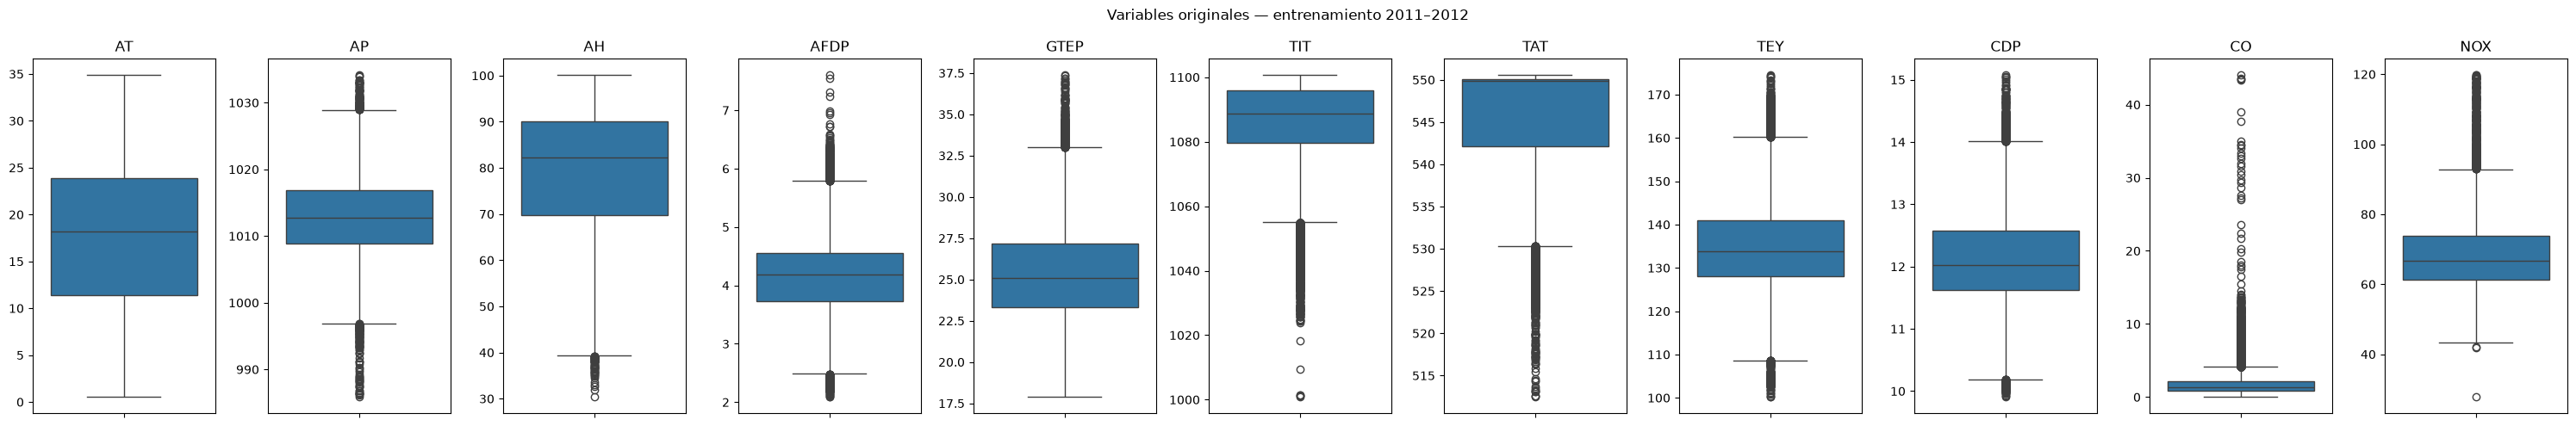

In [8]:
df_entrenamiento = df[df['anio'].isin([2011, 2012])]
columnas = df.columns.drop('anio')

fig, axes = plt.subplots(
    1, len(columnas),
    figsize=(30, 5)
)

for columna, ax in zip(columnas, axes):
    sns.boxplot(y=df_entrenamiento[columna], ax=ax)
    ax.set_title(columna)
    ax.set_ylabel('')

fig.suptitle('Variables originales — entrenamiento 2011–2012')
plt.tight_layout()
plt.show()

En CO, la caja queda cerca de los valores bajos y aparecen muchos puntos por encima del bigote superior, señal de una cola hacia concentraciones altas. NOX también presenta valores extremos principalmente en la parte superior. TIT y TAT tienen cajas concentradas en temperaturas altas y colas hacia valores menores. Conservamos estas observaciones porque las gráficas no permiten determinar si corresponden a errores o a condiciones reales de operación.

Los histogramas muestran qué rangos reúnen más registros y si aparecen varios picos. Usamos 40 intervalos y expresamos sus frecuencias como porcentaje. En la comparación por año se mantienen los mismos intervalos para cada variable y cada año suma 100% por separado, de modo que la diferencia de tamaño entre ambos archivos no determine la comparación.

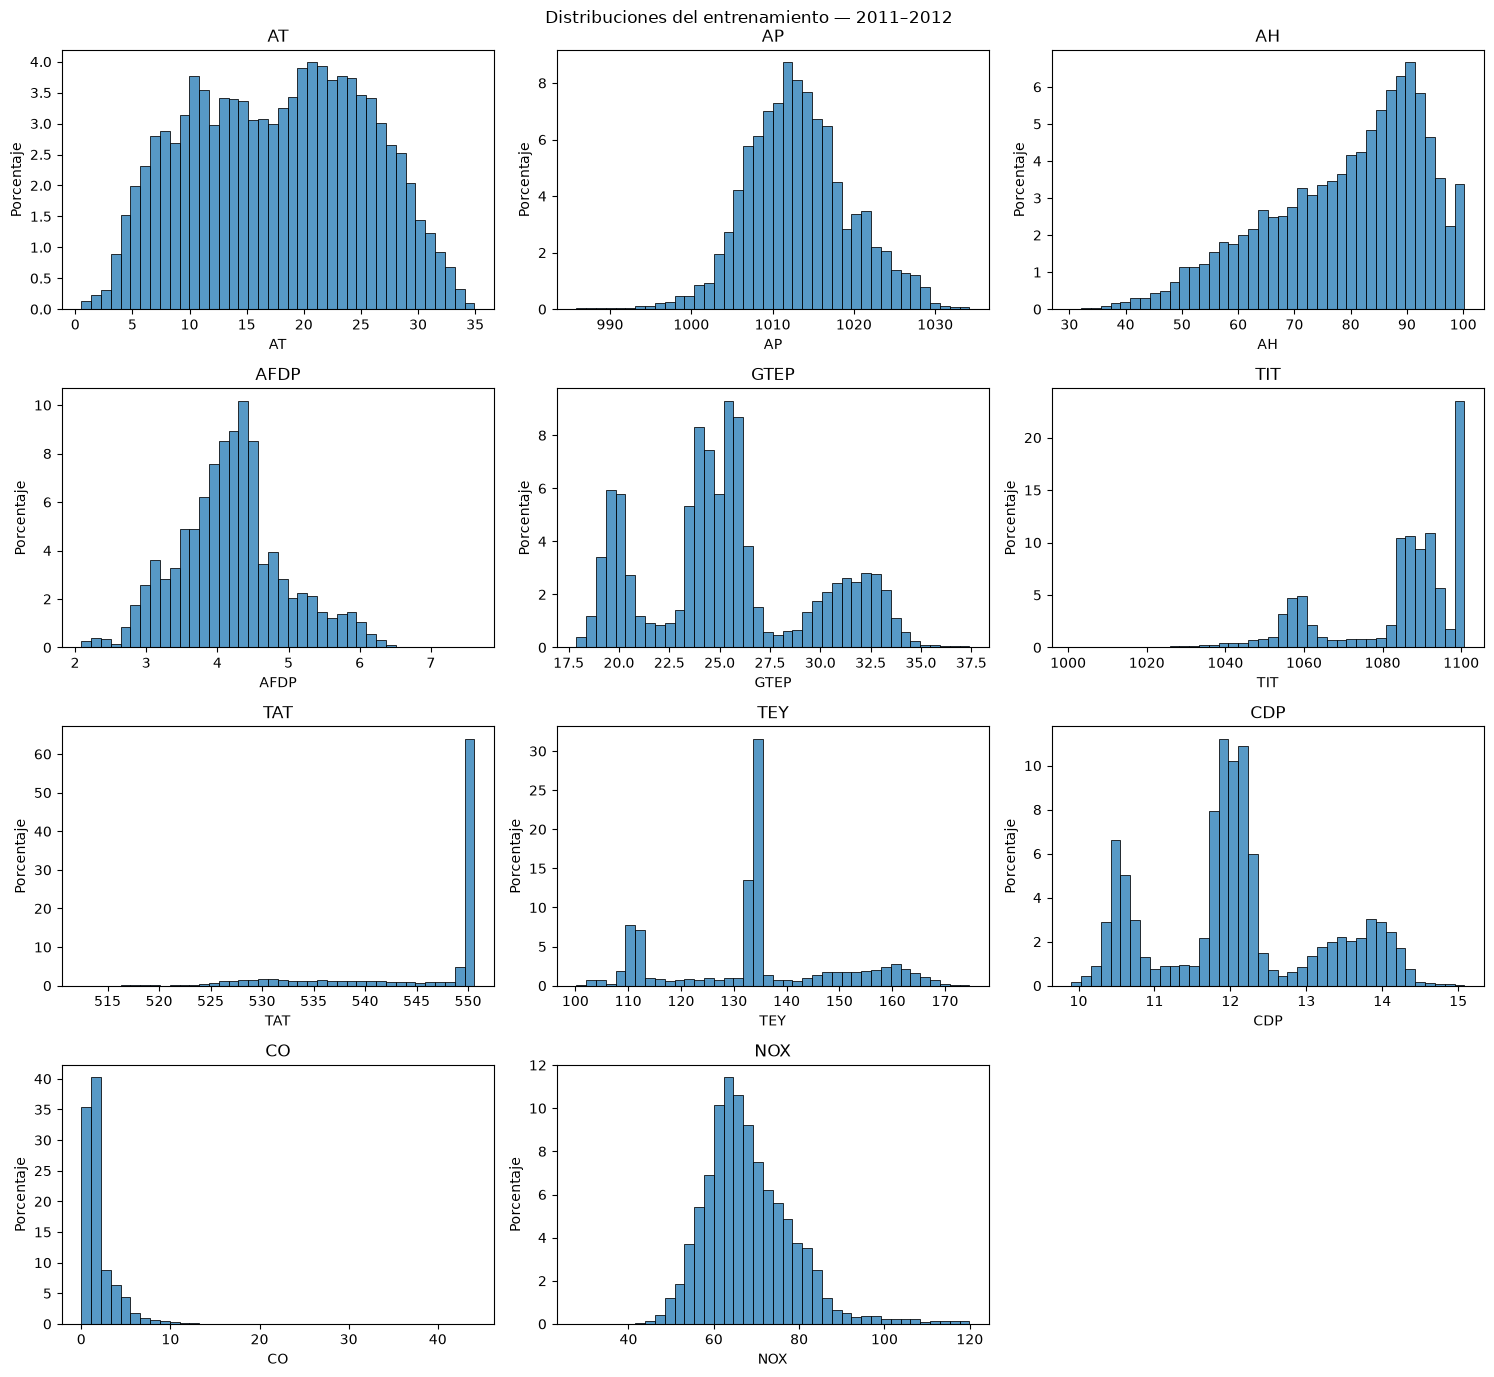

In [9]:
columnas = df.columns.drop('anio')

fig, axes = plt.subplots(4, 3, figsize=(15, 14))

for columna, ax in zip(columnas, axes.flat):
    sns.histplot(
        data=df_entrenamiento,
        x=columna,
        bins=40,
        stat='percent',
        ax=ax
    )
    ax.set_title(columna)
    ax.set_ylabel('Porcentaje')

axes.flat[-1].set_visible(False)

fig.suptitle('Distribuciones del entrenamiento — 2011–2012')
plt.tight_layout()
plt.show()

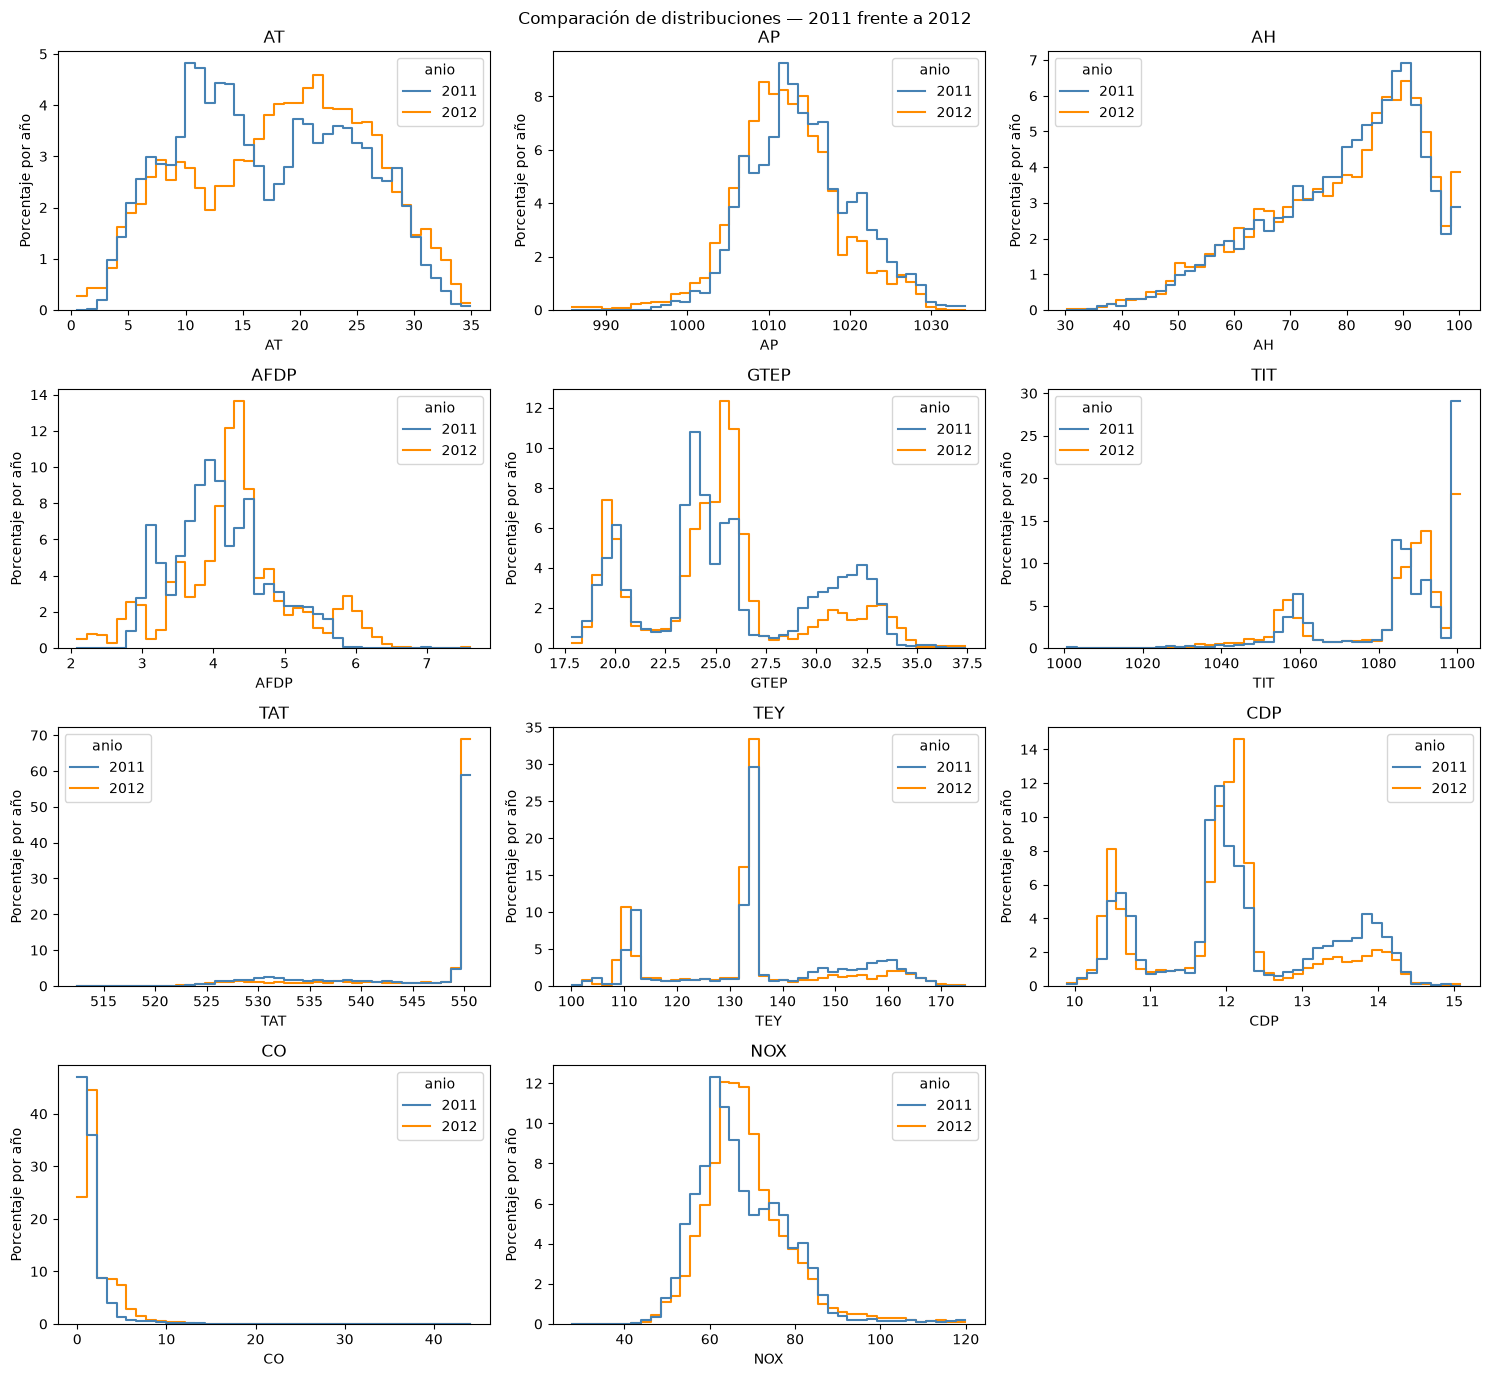

In [10]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))

for columna, ax in zip(columnas, axes.flat):
    sns.histplot(
        data=df_entrenamiento,
        x=columna,
        hue='anio',
        hue_order=[2011, 2012],
        palette={2011: 'steelblue', 2012: 'darkorange'},
        bins=40,
        stat='percent',
        common_bins=True,
        common_norm=False,
        element='step',
        fill=False,
        ax=ax
    )
    ax.set_title(columna)
    ax.set_ylabel('Porcentaje por año')

axes.flat[-1].set_visible(False)

fig.suptitle('Comparación de distribuciones — 2011 frente a 2012')
plt.tight_layout()
plt.show()

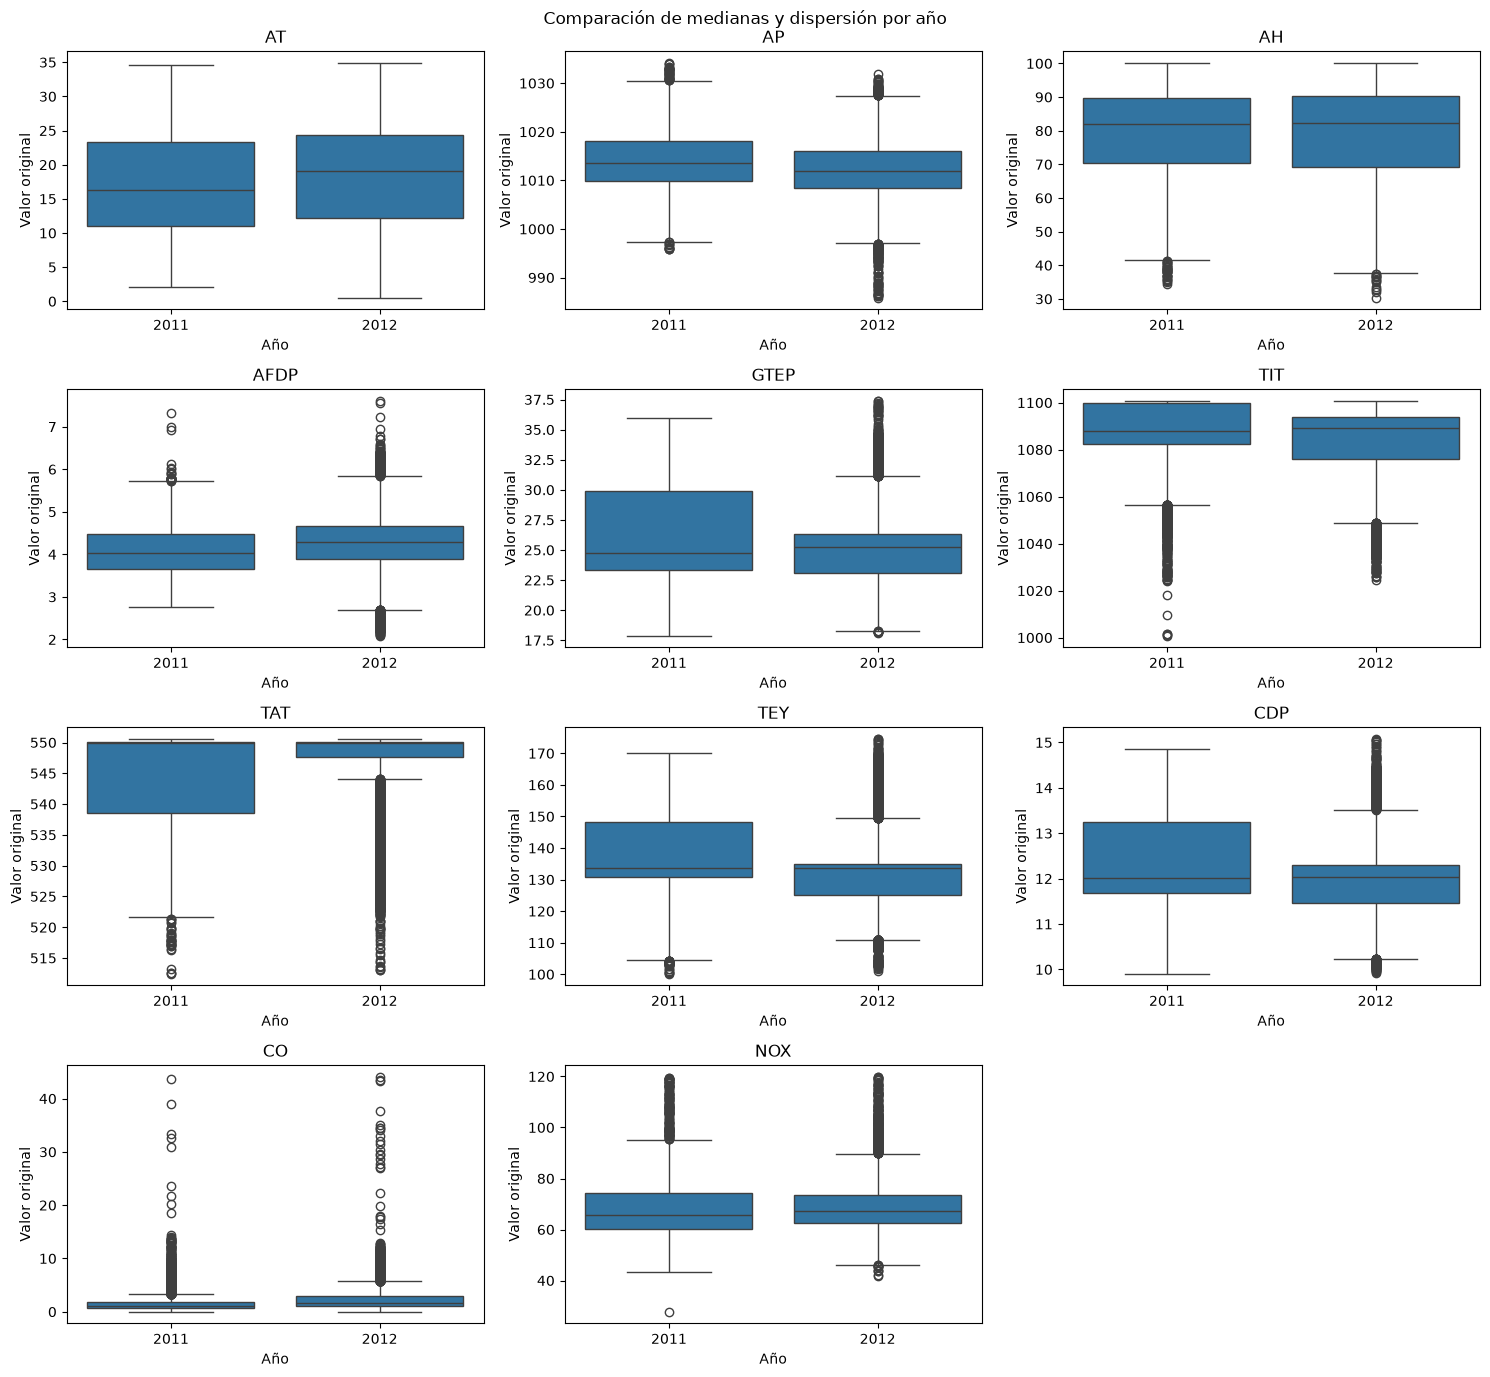

In [11]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))

for columna, ax in zip(columnas, axes.flat):
    sns.boxplot(
        data=df_entrenamiento,
        x='anio',
        y=columna,
        order=[2011, 2012],
        ax=ax
    )
    ax.set_title(columna)
    ax.set_xlabel('Año')
    ax.set_ylabel('Valor original')

axes.flat[-1].set_visible(False)

fig.suptitle('Comparación de medianas y dispersión por año')
plt.tight_layout()
plt.show()

Los histogramas muestran que las variables tienen formas de distribución distintas. CO concentra la mayoría de sus registros en valores bajos y presenta una cola hacia concentraciones altas. En GTEP, TEY y CDP aparecen varios picos separados, es decir, hay rangos de valores que se repiten con mayor frecuencia que los intermedios. Esto podría corresponder a distintas condiciones de operación, aunque las gráficas por sí solas no permiten identificar cuáles. TAT presenta una acumulación especialmente marcada cerca de 550 °C; antes de explicar su causa, habría que revisar cómo se mide y controla esa temperatura.

#### Comparación entre 2011 y 2012
Al comparar los boxplots, la línea de la mediana de AT y AFDP está más arriba en 2012, mientras que la de AP es ligeramente menor. AH tiene medianas y cajas parecidas en ambos años. En GTEP, TEY y CDP, las cajas de 2012 son más estrechas: esto indica que el 50% central de los registros ocupa un intervalo menor. Los histogramas complementan esta observación al mostrar que cambia la proporción de registros en algunos de los picos, aunque ambos años comparten buena parte de sus rangos.
#### Comportamiento de las emisiones
CO mantiene su cola hacia concentraciones altas en ambos años, pero en 2012 su mediana y su caja están más arriba, lo que indica un desplazamiento de la zona central hacia valores mayores. En NOX, los histogramas se superponen ampliamente y las cajas son similares, aunque la mediana de 2012 es ligeramente superior. Estas diferencias describen las emisiones registradas; todavía no permiten atribuir los cambios a una variable operativa o a deterioro de la turbina.
#### Tratamiento de los valores extremos
Por ahora conservaremos los puntos fuera de los bigotes. Cada boxplot calcula sus límites a partir de la distribución del año correspondiente, por lo que una caja más estrecha puede dejar más observaciones fuera de esos límites. Así, tener más puntos señalados en 2012 no demuestra que existan más errores de medición. Para decidir si alguno requiere tratamiento, necesitaremos revisar sus valores y su contexto operativo.

## 9. Matriz de correlación

Calculamos la correlación de Pearson con `df.corr()` y la mostramos con `sns.heatmap`, siguiendo el ejemplo de selección de variables del profesor. Un valor cercano a 1 indica una relación lineal ascendente; cerca de −1, descendente. Un valor próximo a cero indica poca relación lineal, aunque puede existir una relación curva.

Excluimos `anio` porque identifica el periodo y CO porque proponemos estimar NOX sin depender del otro analizador de gases. NOX permanece en la matriz como respuesta de interés. No estandarizamos para calcular esta matriz: la correlación de Pearson no cambia al aplicar estandarización o Min-Max a columnas no constantes.

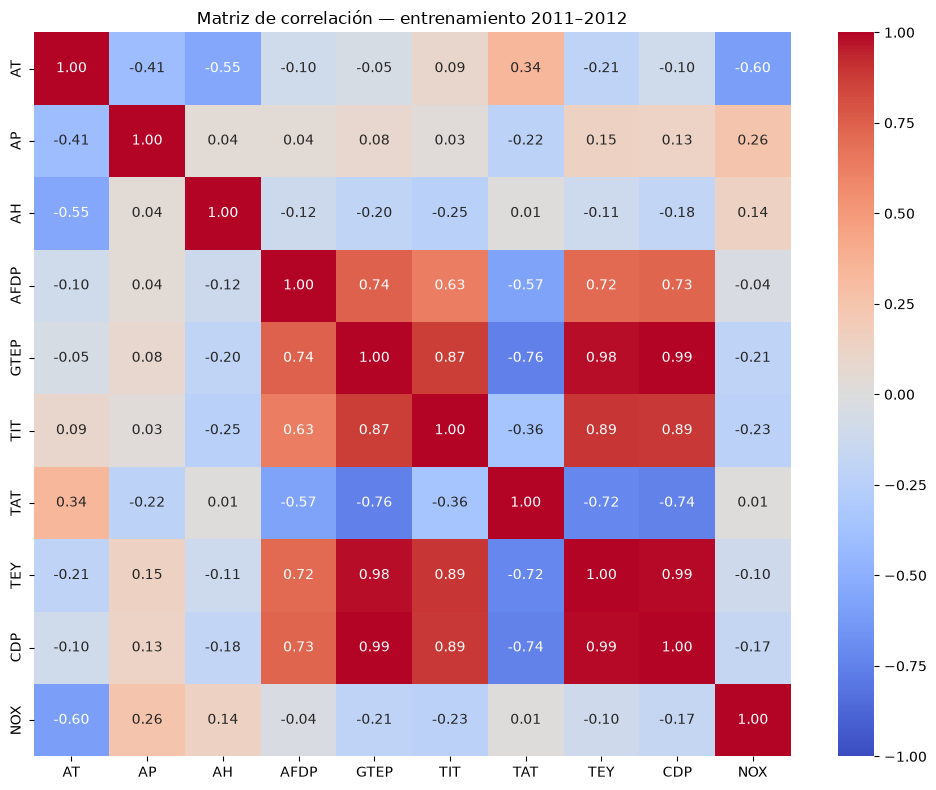

AT     -0.600006
TIT    -0.231636
GTEP   -0.208496
CDP    -0.169103
TEY    -0.102631
AFDP   -0.037299
TAT     0.009888
AH      0.143061
AP      0.256744
Name: NOX, dtype: float64

In [12]:
columnas = [
    'AT', 'AP', 'AH', 'AFDP', 'GTEP',
    'TIT', 'TAT', 'TEY', 'CDP', 'NOX'
]

matriz_correlacion = df_entrenamiento[columnas].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_correlacion,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)
plt.title('Matriz de correlación — entrenamiento 2011–2012')
plt.tight_layout()
plt.show()
matriz_correlacion['NOX'].drop('NOX').sort_values()

## 10. Interpretación de las correlaciones

AT presenta la mayor correlación lineal con NOX (−0.60): en los registros de entrenamiento, temperaturas ambientales mayores tienden a acompañarse de concentraciones menores de NOX. Esto describe una asociación y no demuestra que la temperatura sea la causa del cambio. Las demás variables tienen correlaciones de menor magnitud; destacan AP (0.26), TIT (−0.23) y GTEP (−0.21). AFDP (−0.04) y TAT (0.01) muestran poca relación lineal individual con NOX, aunque podrían tener relaciones curvas o aportar información al combinarse con otras variables.

Entre los posibles predictores aparecen correlaciones muy altas: GTEP con TEY (0.98), GTEP con CDP (0.99) y TEY con CDP (0.99). Esto indica que estas mediciones varían de forma muy parecida y podrían aportar información redundante. Si las incluimos juntas en una regresión lineal, puede resultar difícil distinguir el aporte individual de cada una. Por ahora las conservaremos; revisaremos estas relaciones antes de seleccionar las entradas del modelo.

## 11. Dispersión de AT frente a NOX

Revisamos la relación con mayor correlación absoluta mediante `sns.scatterplot`, como en el ejemplo de regresión lineal del profesor. Cada punto representa un registro de entrenamiento; la transparencia permite apreciar dónde se acumulan observaciones. Todavía no ajustamos una recta.

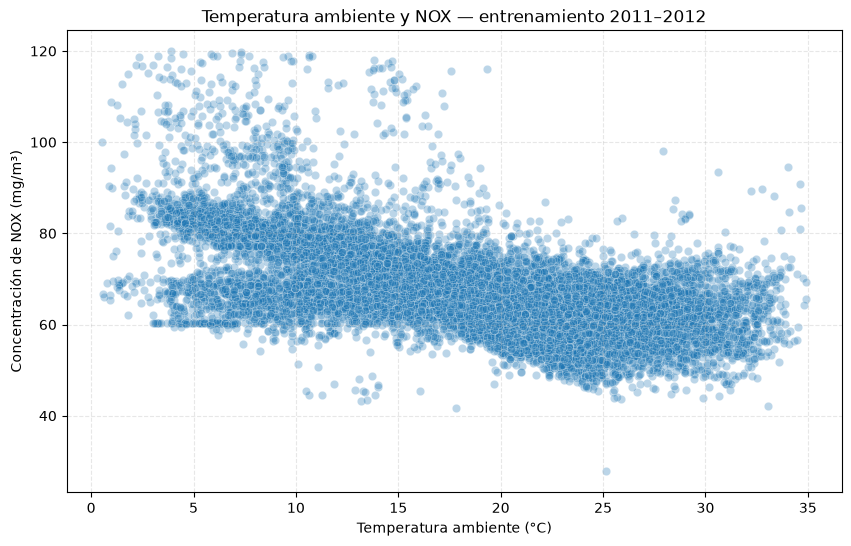

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='AT',
    y='NOX',
    data=df_entrenamiento,
    alpha=0.3
)

plt.xlabel('Temperatura ambiente (°C)')
plt.ylabel('Concentración de NOX (mg/m³)')
plt.title('Temperatura ambiente y NOX — entrenamiento 2011–2012')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()


La nube de puntos desciende en términos generales: a temperaturas ambientales mayores suelen observarse concentraciones menores de NOX, lo que coincide con la correlación de −0.60. Para una misma temperatura aparecen emisiones distintas; AT por sí sola no determina el valor de NOX. La dispersión también parece mayor a temperaturas bajas, algo que habrá que considerar al revisar el ajuste de una regresión. La gráfica no permite atribuir una causa física a estas diferencias.

## 12. Avance y siguiente etapa

Completamos la carga, la revisión de tipos y faltantes y una primera exploración de 2011 y 2012. Conservamos las once variables originales y todas las observaciones. Los conjuntos completos de validación y prueba y las tablas `X` e `y` siguen pendientes; los años posteriores no se han usado para las gráficas ni para elegir entradas.

El siguiente paso será definir las entradas y preparar los tres conjuntos por año siguiendo los ejemplos del profesor. La propuesta es comparar variables ambientales con ambientales más operativas para estimar NOX de la misma hora. `anio`, CO y NOX no serán entradas.

Decidiremos el escalado según el modelo: la regresión lineal ordinaria con intercepto puede trabajar en unidades originales, mientras que modelos como Ridge, Lasso o SVM normalmente requieren atender la escala. Estandarizar cambia el centro y la escala; no convierte una distribución en normal. Si aplicamos un escalador, sus parámetros se calcularán sólo con entrenamiento y se reutilizarán en validación y prueba. Todavía no hay modelos, métricas ni resultados de evaluación.